In [26]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import SilhouetteVisualizer

In [2]:
X,y,c= make_blobs(n_samples= 500, cluster_std= 0.8, centers= 4, n_features= 2, return_centers= True)

df= pd.DataFrame({
    "x1": X[:,0],
    "x2": X[:,1],
    "y": y
})

df.head()

,x1,x2,y
0,3.776437,-5.833612,1
1,2.919047,3.782393,0
2,2.435060,-4.423629,1
3,4.663701,-4.406115,1
4,3.733576,2.845469,0


In [3]:
df_centers= pd.DataFrame({
    "x1": c[:,0],
    "x2": c[:,1],
})

df_centers.head()

,x1,x2
0,3.187614,2.576980
1,3.379970,-4.903477
2,7.413045,-8.246391
3,7.705221,-1.953223


<Axes: xlabel='x1', ylabel='x2'>

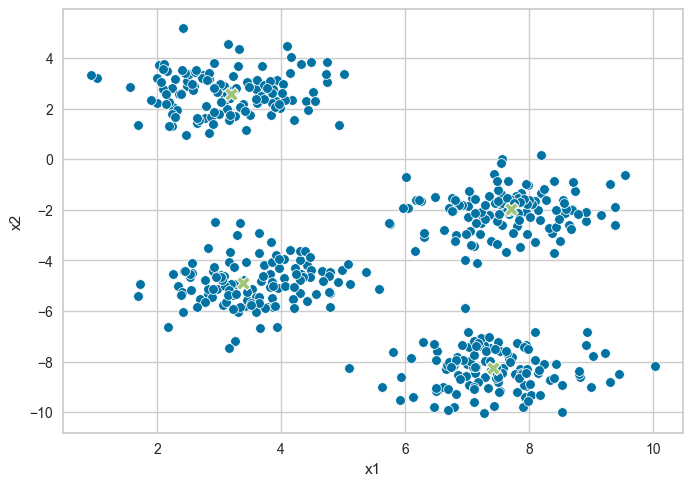

In [6]:
sns.scatterplot(data= df, x= "x1", y= "x2")
sns.scatterplot(data= df_centers, x= "x1", y= "x2", marker= "X", s=100)

In [11]:
kmeans= KMeans(n_clusters=4)
df_cluster= kmeans.fit_predict(X)
df["cluster"]= df_cluster
kmeans_centers= kmeans.cluster_centers_

df_kmeans_centers= pd.DataFrame(
    {
        "x1": kmeans_centers[:,0],
        "x2": kmeans_centers[:,1]
    }
)

df_kmeans_centers.head()


,x1,x2
0,3.557442,-4.903237
1,3.121823,2.659372
2,7.432921,-8.315767
3,7.632063,-2.046235


<Axes: xlabel='x1', ylabel='x2'>

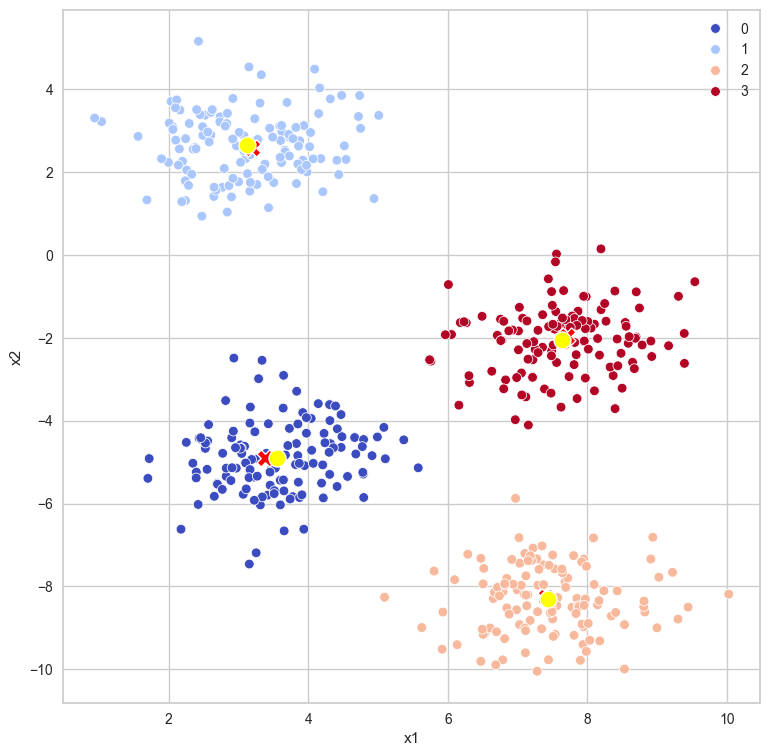

In [12]:
plt.figure(figsize=(9,9))
sns.scatterplot(data= df, x= "x1", y= "x2", hue= df.cluster, palette= "coolwarm")
sns.scatterplot(data= df_centers, x= "x1", y= "x2", marker= "X", s=150, color= "red")
sns.scatterplot(data= df_kmeans_centers, x= "x1", y= "x2", marker= "o", s=150, color= "yellow")

In [15]:
def visualize_cluster(k):
    kmeans= KMeans(n_clusters=k)
    df_cluster= kmeans.fit_predict(X)
    df["cluster"]= df_cluster
    kmeans_centers= kmeans.cluster_centers_

    df_kmeans_centers= pd.DataFrame(
        {
            "x1": kmeans_centers[:,0],
            "x2": kmeans_centers[:,1]
        }
    )
    plt.figure(figsize=(9,9))
    sns.scatterplot(data= df, x= "x1", y= "x2", hue= df.cluster, palette= "coolwarm")
    sns.scatterplot(data= df_centers, x= "x1", y= "x2", marker= "X", s=150, color= "red")
    sns.scatterplot(data= df_kmeans_centers, x= "x1", y= "x2", marker= "o", s=150, color= "yellow")

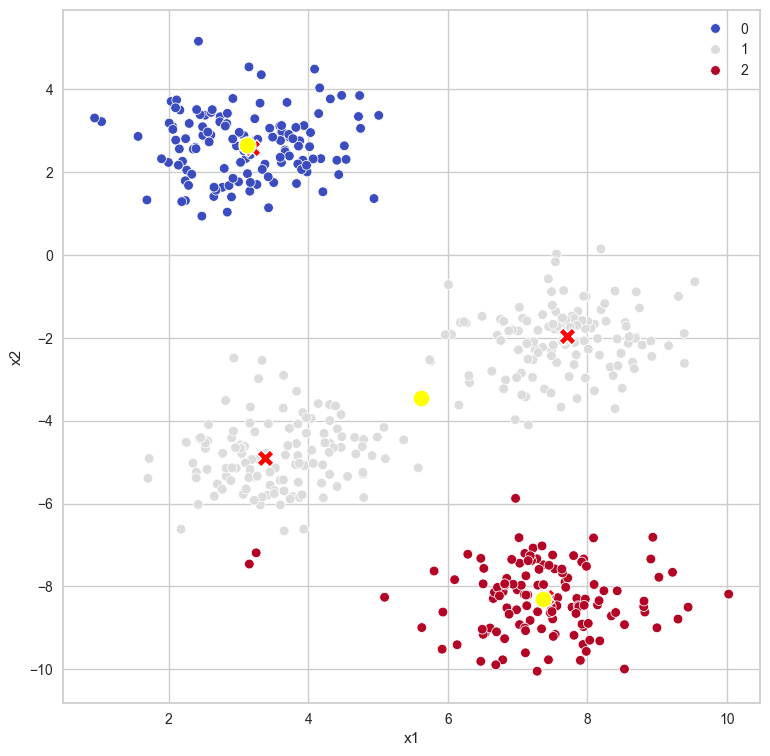

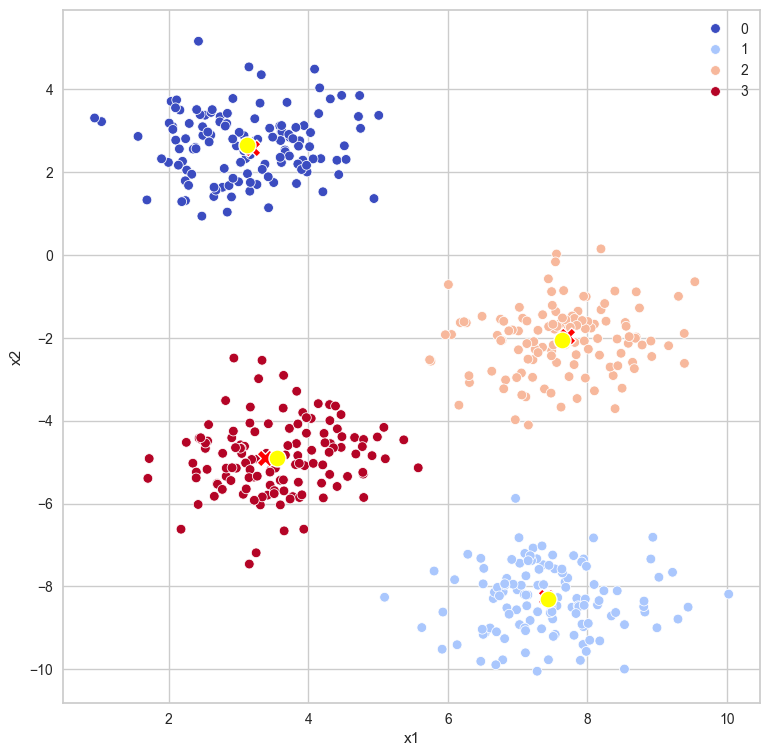

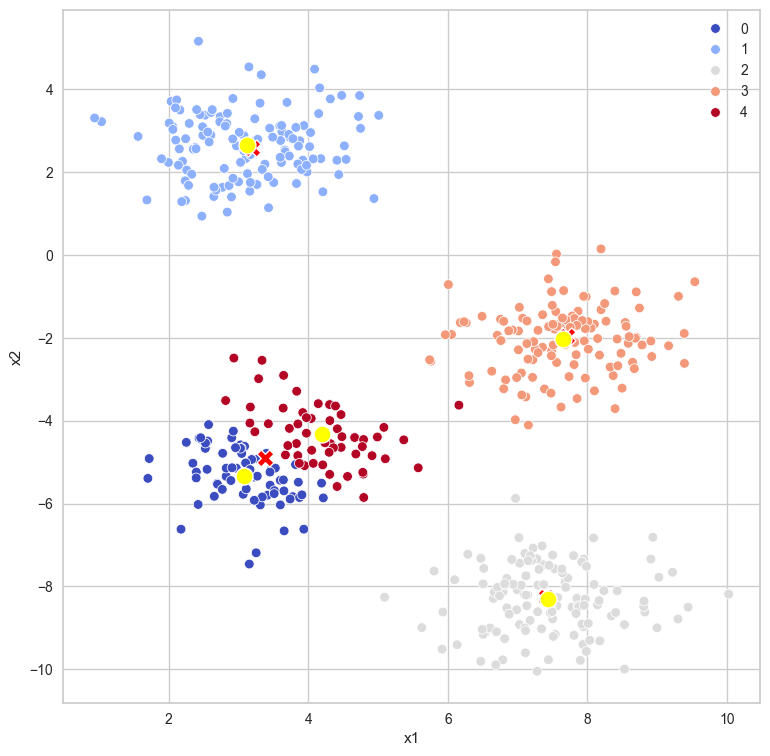

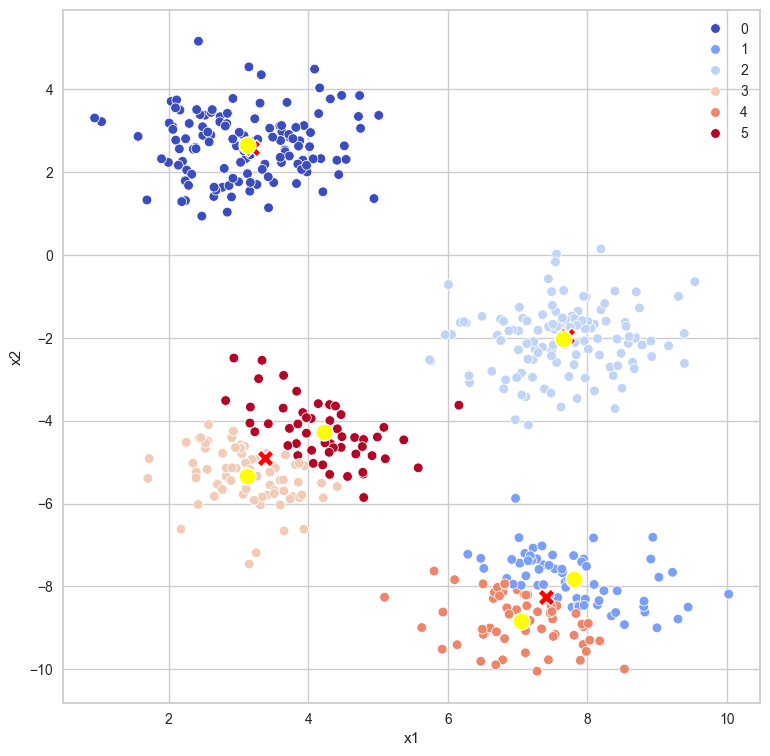

In [21]:
for i in range(3,7):
    visualize_cluster(i)

Encontrar el valor optimo de K

Text(0, 0.5, 'Inertia')

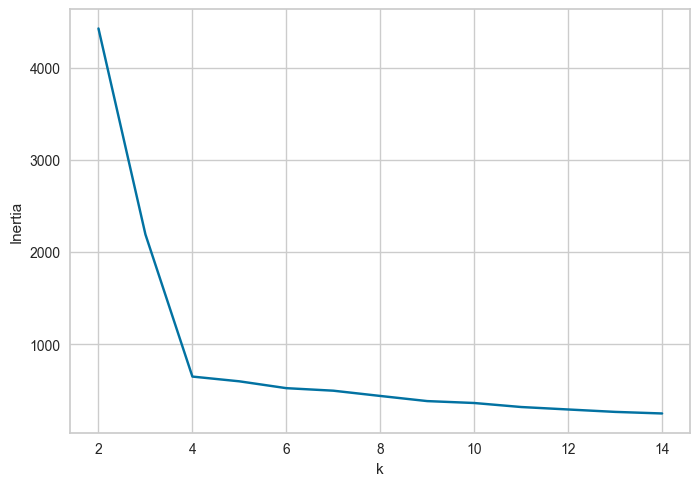

In [22]:
sum_squared_distances= []
K= range(2,15)

for k in K:
    km= KMeans(n_clusters=k)
    km= km.fit(X)
    sum_squared_distances.append(km.inertia_)

plt.plot(K, sum_squared_distances, "bx-")
plt.xlabel("k")
plt.ylabel("Inertia")

#El codo es el que indica el numero de clusters optimo, en este caso, 3 o 4.

Text(0, 0.5, 'Silhuoette scores')

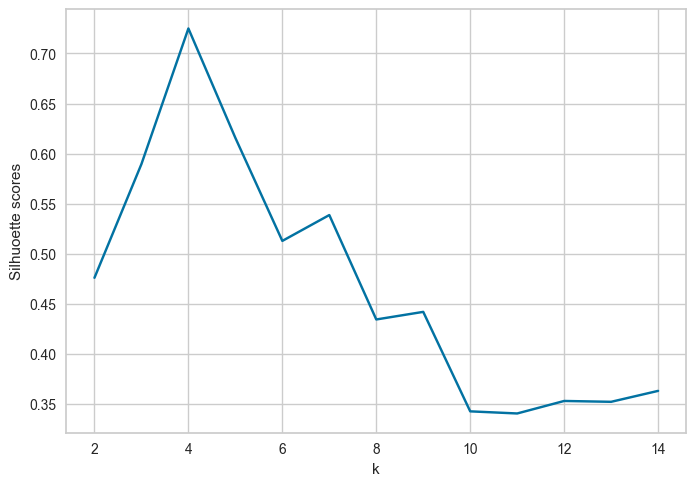

In [30]:
silhuoette_scores= []
K= range(2,15)

for k in K:
    km= KMeans(n_clusters=k)
    km= km.fit(X)
    y= km.predict(X)
    silhuoette_scores.append(silhouette_score(X,y))

plt.plot(K, silhuoette_scores, "bx-")
plt.xlabel("k")
plt.ylabel("Silhuoette scores")

#El valor mas alto es el que indica el numero de clusters optimo, en este caso 4

Silhouette score: 0.7249991335883237


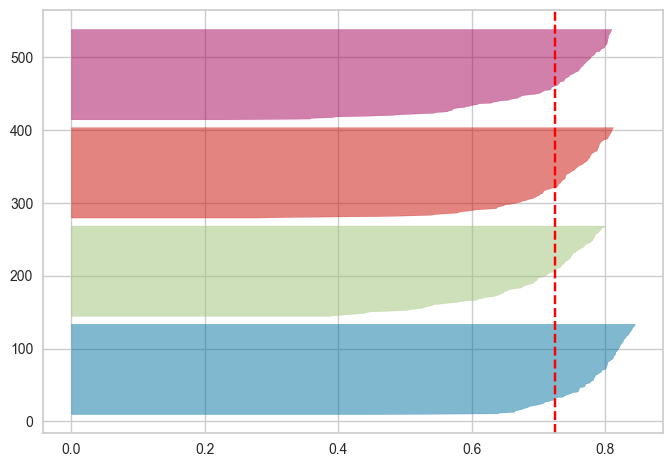

In [44]:
km= KMeans(n_clusters=4)
visualizer= SilhouetteVisualizer(km, colors= "yellowbrick")
visualizer.fit(X)

print(f"Silhouette score: {silhouette_score(X,km.predict(X))}")

0.7249991335883237